# Bài tập tuần 6: Transfer Learning trên FGVC-Aircraft

**Đặng Văn Chung · 24174800194 · DHKM18A2HN**

## Bước 1. Chuẩn bị dữ liệu

### 1.1. Cài đặt cấu hình và kiểm tra GPU

Kiểm tra phiên PyTorch thiết bị

In [1]:
import copy
import os
import random
import shutil
import subprocess
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms

SEED = 42
IMAGE_SIZE, RESIZE_SIZE, BATCH_SIZE = 160, 176, 64
PROBE_EPOCHS, PARTIAL_EPOCHS, FROZEN_BLOCKS = 12, 8, 6
if not torch.cuda.is_available():
    gpu_list = (
        subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True)
        if shutil.which("nvidia-smi") else None
    )
    if gpu_list is None or gpu_list.returncode != 0 or not gpu_list.stdout.strip():
        raise RuntimeError(
            "Phiên Colab chưa nhận GPU. Chọn GPU T4, bấm Lưu, kết nối lại "
            "rồi chạy lại ô 1.1."
        )
    print(gpu_list.stdout.strip())
    if torch.version.cuda is None:
        raise RuntimeError(
            "Colab thấy GPU nhưng PyTorch hiện tại là bản CPU. "
            "Nếu đã cài PyTorch bản CPU, hãy bỏ lệnh cài và mở phiên GPU mới."
        )
    raise RuntimeError(
        f"Colab thấy GPU và PyTorch hỗ trợ CUDA {torch.version.cuda}, "
        "nhưng CUDA chưa khả dụng. Khởi động lại phiên và chạy ô 1.1 trước."
    )

device = torch.device("cuda:0")
try:
    torch.ones(1, device=device).sum().item()
except RuntimeError as error:
    raise RuntimeError(
        f"PyTorch nhận GPU nhưng phép tính CUDA thất bại: {error}"
    ) from error

print(f"GPU: {torch.cuda.get_device_name(device)}")
print(f"Thiết bị: {device} | PyTorch CUDA: {torch.version.cuda}")
torch.set_num_threads(min(6, os.cpu_count() or 1))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

GPU: Tesla T4
Thiết bị: cuda:0 | PyTorch CUDA: 13.0


### 1.2. Tiền xử lý ảnh

Cắt 20 pixel ở đáy ảnh, resize cạnh ngắn về 176, cắt giữa 160 × 160 và chuẩn hóa theo ImageNet. Kích thước 160 dùng cho lượt chạy CPU.

In [2]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
recipe = weights.transforms()
mean, std = tuple(recipe.mean), tuple(recipe.std)

def remove_banner(img):
    return img.crop((0, 0, img.width, img.height - 20))

preprocess = transforms.Compose([
    remove_banner,
    transforms.Resize(RESIZE_SIZE, interpolation=recipe.interpolation),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

### 1.3. Nạp train và validation

Mở hai tập chính thức và kiểm tra cùng đủ 100 nhãn biến thể máy bay.

In [3]:
data_root = Path(os.environ.get("AIRCRAFT_DATA_ROOT", "./data"))

def aircraft(split, download=False):
    return datasets.FGVCAircraft(
        data_root, split=split, annotation_level="variant",
        transform=preprocess, download=download,
    )

try:
    train_set = aircraft("train")
except RuntimeError:
    train_set = aircraft("train", download=True)
val_set = aircraft("val")
names = train_set.classes
assert names == val_set.classes and len(names) == 100
print(f"Train: {len(train_set):,} | Validation: {len(val_set):,} | Số lớp: {len(names)}")

100%|██████████| 2.75G/2.75G [01:51<00:00, 24.8MB/s]


Train: 3,334 | Validation: 3,333 | Số lớp: 100


## Bước 2. Chuẩn bị EfficientNet-B0

### 2.1. Nạp trọng số và thay lớp cuối

Dùng trọng số ImageNet-1K, thay lớp cuối thành 100 logit và đóng băng backbone.

In [4]:
model = models.efficientnet_b0(weights=weights)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(names))
model = model.to(device=device, memory_format=torch.channels_last)
model.requires_grad_(False)
model.classifier.requires_grad_(True)
prefix = model.features[:FROZEN_BLOCKS]
tail = model.features[FROZEN_BLOCKS:]
criterion = nn.CrossEntropyLoss()
print(f"Mô hình đang ở: {next(model.parameters()).device}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


Mô hình đang ở: cuda:0


### 2.2. Tạo hàm trích xuất đặc trưng

Đọc ảnh theo batch và lấy đầu ra của sáu khối đầu ở chế độ đánh giá.

In [7]:
def image_loader(dataset):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=0, pin_memory=device.type == "cuda")

def move_images(images):
    if images.ndim == 4:
        return images.to(device, non_blocking=True, memory_format=torch.channels_last)
    return images.to(device, non_blocking=True)

@torch.no_grad()
def cache_prefix(dataset):
    prefix.eval()
    features, targets = [], []
    for images, labels in image_loader(dataset):
        features.append(prefix(move_images(images)).cpu())
        targets.append(labels)
    return TensorDataset(torch.cat(features), torch.cat(targets))

### 2.3. Tính và lưu đặc trưng

Tạo cache train và validation để tái sử dụng trong hai giai đoạn huấn luyện.

In [8]:
start_cache = perf_counter()
train_features = cache_prefix(train_set)
print("Đã trích xuất đặc trưng train.", flush=True)
val_features = cache_prefix(val_set)
cache_seconds = perf_counter() - start_cache
train_loader = DataLoader(train_features, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_features, batch_size=BATCH_SIZE, shuffle=False)
total_parameters = sum(p.numel() for p in model.parameters())
print(f"Tham số: {total_parameters:,} | Cache train: {tuple(train_features.tensors[0].shape)}")
print(f"Thời gian tạo cache: {cache_seconds:.1f} s")

Đã trích xuất đặc trưng train.
Tham số: 4,135,648 | Cache train: (3334, 112, 10, 10)
Thời gian tạo cache: 138.6 s


## Bước 3. Huấn luyện và chọn checkpoint

### 3.1. Xử lý một epoch

Cập nhật trọng số ở lượt train và tính loss, top-1, top-5, macro-F1 sau mỗi lượt.

In [9]:
def tail_logits(features):
    output = tail(features)
    return model.classifier(model.avgpool(output).flatten(1))

def run_epoch(loader, forward, optimizer=None):
    training = optimizer is not None
    model.eval()
    model.classifier.train(training)
    loss_sum = 0.0
    targets, predictions, top5_matches = [], [], []
    with torch.set_grad_enabled(training):
        for batch, labels in loader:
            labels = labels.to(device)
            logits = forward(move_images(batch))
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            top5 = logits.detach().topk(5, dim=1).indices
            loss_sum += loss.item() * len(labels)
            predictions.append(top5[:, 0].cpu())
            top5_matches.append(top5.eq(labels[:, None]).any(1).cpu())
            targets.append(labels.cpu())
    truth = torch.cat(targets).numpy()
    pred = torch.cat(predictions).numpy()
    return {
        "loss": loss_sum / len(truth), "acc": float((truth == pred).mean()),
        "top5": float(torch.cat(top5_matches).float().mean()),
        "macro_f1": f1_score(truth, pred, average="macro",
                             labels=np.arange(len(names)), zero_division=0),
        "truth": truth, "pred": pred,
    }

### 3.2. Lưu trọng số tốt nhất

Theo dõi validation loss sau mỗi epoch và khôi phục trọng số ứng với loss thấp nhất.

In [10]:
def fit(stage, optimizer, epochs, train_data, val_data, forward):
    started = perf_counter()
    history = []
    best_row, best_state = None, None
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    for epoch in range(1, epochs + 1):
        train = run_epoch(train_data, forward, optimizer)
        val = run_epoch(val_data, forward)
        row = {
            "stage": stage, "epoch": epoch, "train_loss": train["loss"],
            "train_acc": train["acc"], "val_loss": val["loss"],
            "val_acc": val["acc"], "val_top5": val["top5"],
            "val_macro_f1": val["macro_f1"], "trainable_parameters": trainable,
        }
        history.append(row)
        if best_row is None or row["val_loss"] < best_row["val_loss"]:
            best_row = row.copy()
            best_state = copy.deepcopy(model.state_dict())
        print(f"{stage} {epoch:02d}/{epochs}: train {train['acc']:.2%} | "
              f"val {val['acc']:.2%} | val loss {val['loss']:.4f}", flush=True)
    best_row["seconds"] = perf_counter() - started
    model.load_state_dict(best_state)
    return history, best_row, best_state

### 3.3. Chuẩn bị vector cho Linear Probe

Tính trước vector 1.280 chiều của từng ảnh khi backbone còn đóng băng.

In [11]:
@torch.no_grad()
def probe_loader(feature_data, shuffle=False):
    tail.eval()
    embeddings, targets = [], []
    for features, labels in DataLoader(feature_data, batch_size=BATCH_SIZE):
        output = tail(move_images(features))
        embeddings.append(model.avgpool(output).flatten(1).cpu())
        targets.append(labels)
    vector_data = TensorDataset(torch.cat(embeddings), torch.cat(targets))
    return DataLoader(vector_data, batch_size=BATCH_SIZE, shuffle=shuffle)

probe_cache_started = perf_counter()
probe_train_loader = probe_loader(train_features, shuffle=True)
probe_val_loader = probe_loader(val_features)
probe_cache_seconds = perf_counter() - probe_cache_started

### 3.4. Chạy Linear Probe

Chỉ học classifier trong 12 epoch với learning rate 0,003.

In [12]:
probe_optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=3e-3, weight_decay=1e-3)
probe_history, probe_best, probe_state = fit(
    "Linear Probe", probe_optimizer, PROBE_EPOCHS, probe_train_loader, probe_val_loader, model.classifier
)

Linear Probe 01/12: train 11.28% | val 19.74% | val loss 3.4863
Linear Probe 02/12: train 34.25% | val 24.45% | val loss 3.1524
Linear Probe 03/12: train 45.44% | val 29.64% | val loss 2.9447
Linear Probe 04/12: train 53.51% | val 31.14% | val loss 2.8372
Linear Probe 05/12: train 58.46% | val 32.91% | val loss 2.7405
Linear Probe 06/12: train 64.52% | val 34.26% | val loss 2.6846
Linear Probe 07/12: train 68.72% | val 35.37% | val loss 2.6462
Linear Probe 08/12: train 71.63% | val 35.73% | val loss 2.6097
Linear Probe 09/12: train 74.69% | val 36.00% | val loss 2.5996
Linear Probe 10/12: train 77.08% | val 36.27% | val loss 2.5660
Linear Probe 11/12: train 77.50% | val 37.32% | val loss 2.5603
Linear Probe 12/12: train 80.71% | val 37.92% | val loss 2.5428


### 3.5. Chạy Partial Fine-Tuning

Mở ba khối cuối từ checkpoint Linear Probe tốt nhất. Chạy 8 epoch với learning rate 0,0003 cho backbone và 0,001 cho classifier.

In [13]:
tail.requires_grad_(True)
partial_optimizer = torch.optim.AdamW([
    {"params": tail.parameters(), "lr": 3e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-3)
partial_history, partial_best, partial_state = fit(
    "Partial FT", partial_optimizer, PARTIAL_EPOCHS, train_loader, val_loader, tail_logits
)

Partial FT 01/8: train 75.73% | val 41.01% | val loss 2.4945
Partial FT 02/8: train 89.47% | val 44.67% | val loss 2.4699
Partial FT 03/8: train 94.99% | val 44.79% | val loss 2.7465
Partial FT 04/8: train 95.62% | val 45.93% | val loss 2.7488
Partial FT 05/8: train 97.60% | val 47.73% | val loss 2.6420
Partial FT 06/8: train 98.83% | val 45.54% | val loss 2.9096
Partial FT 07/8: train 99.25% | val 47.04% | val loss 2.9873
Partial FT 08/8: train 99.82% | val 48.75% | val loss 2.9615


### 3.6. Chọn checkpoint để đánh giá

So sánh hai giai đoạn trên validation và nạp checkpoint có loss thấp nhất.

In [14]:
selected, selected_state = min(
    [(probe_best, probe_state), (partial_best, partial_state)],
    key=lambda item: item[0]["val_loss"],
)
model.load_state_dict(selected_state)
history = pd.DataFrame(probe_history + partial_history)
display(pd.DataFrame([probe_best, partial_best]).round(4))
print(f"Chọn {selected['stage']}, epoch {selected['epoch']}, validation loss {selected['val_loss']:.4f}")

,stage,epoch,train_loss,train_acc,val_loss,val_acc,val_top5,val_macro_f1,trainable_parameters,seconds
0,Linear Probe,12,0.9905,0.8071,2.5428,0.3792,0.6637,0.370,128100,2.7748
1,Partial FT,2,0.3778,0.8947,2.4699,0.4467,0.7438,0.444,3283840,20.8514


Chọn Partial FT, epoch 2, validation loss 2.4699


## Bước 4. Đánh giá và phân tích lỗi

### 4.1. Đánh giá trên test

Tính loss, top-1, top-5 và macro-F1 của checkpoint đã chọn.

In [15]:
test_set = aircraft("test")
assert test_set.classes == names
test = run_epoch(image_loader(test_set), model)
print(f"Test {len(test_set):,} ảnh | Loss {test['loss']:.4f} | "
      f"Top-1 {test['acc']:.2%} | Top-5 {test['top5']:.2%} | Macro-F1 {test['macro_f1']:.4f}")

Test 3,333 ảnh | Loss 2.5128 | Top-1 43.11% | Top-5 74.05% | Macro-F1 0.4298


### 4.2. Vẽ đường học

Vẽ loss và accuracy của train và validation qua hai giai đoạn.

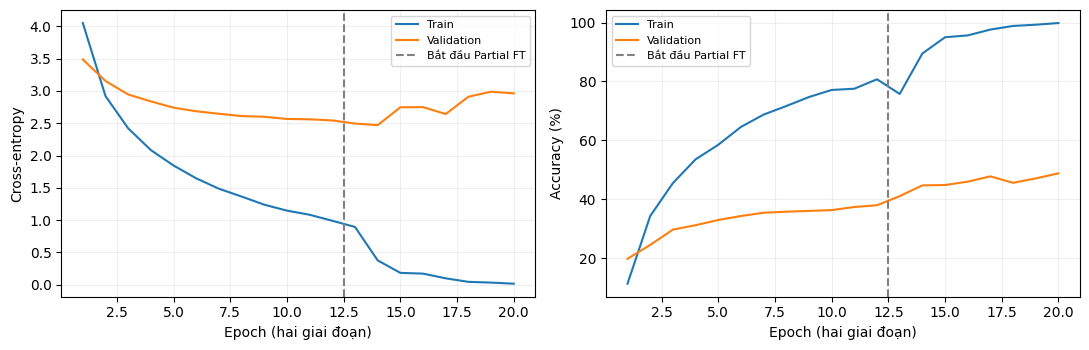

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
epochs = np.arange(1, len(history) + 1)
for ax, metric, title in zip(axes, ("loss", "acc"), ("Cross-entropy", "Accuracy (%)")):
    scale = 100 if metric == "acc" else 1
    ax.plot(epochs, history[f"train_{metric}"] * scale, label="Train")
    ax.plot(epochs, history[f"val_{metric}"] * scale, label="Validation")
    ax.axvline(PROBE_EPOCHS + 0.5, linestyle="--", color="0.5", label="Bắt đầu Partial FT")
    ax.set(xlabel="Epoch (hai giai đoạn)", ylabel=title)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 4.3. Tìm cặp lớp dễ nhầm

Cộng lỗi hai chiều theo từng cặp và liệt kê 10 lớp có F1 thấp nhất.

In [17]:
cm = confusion_matrix(test["truth"], test["pred"], labels=np.arange(len(names)))
pairs = sorted(
    ((int(cm[i, j] + cm[j, i]), names[i], names[j])
     for i in range(len(names)) for j in range(i + 1, len(names))),
    reverse=True,
)
display(pd.DataFrame(pairs[:10], columns=["Số lỗi hai chiều", "Variant A", "Variant B"]))
per_class = classification_report(
    test["truth"], test["pred"], labels=np.arange(len(names)), target_names=names,
    output_dict=True, zero_division=0,
)
display(pd.DataFrame(per_class).T.loc[names].sort_values("f1-score").head(10).round(4))

,Số lỗi hai chiều,Variant A,Variant B
0,22,C-47,DC-3
1,18,E-190,E-195
2,17,BAE 146-200,BAE 146-300
3,17,ATR-42,ATR-72
4,15,ATR-42,Dornier 328
5,14,DC-10,L-1011
6,13,Boeing 717,DC-9-30
7,12,Gulfstream IV,Gulfstream V
8,12,CRJ-700,CRJ-900
9,12,737-800,737-900


,precision,recall,f1-score,support
737-300,0.0000,0.0000,0.0000,33.0
757-200,0.0571,0.0588,0.0580,34.0
A330-200,0.2222,0.0606,0.0952,33.0
767-300,0.0862,0.1471,0.1087,34.0
737-200,0.2000,0.0882,0.1224,34.0
737-800,0.1136,0.1471,0.1282,34.0
747-100,0.2308,0.0909,0.1304,33.0
737-700,0.1159,0.2424,0.1569,33.0
A320,0.1212,0.2424,0.1616,33.0
737-400,0.1852,0.1515,0.1667,33.0


### 4.4. Vẽ ma trận nhầm lẫn

Biểu diễn số lượt dự đoán theo nhãn thật và nhãn dự đoán.

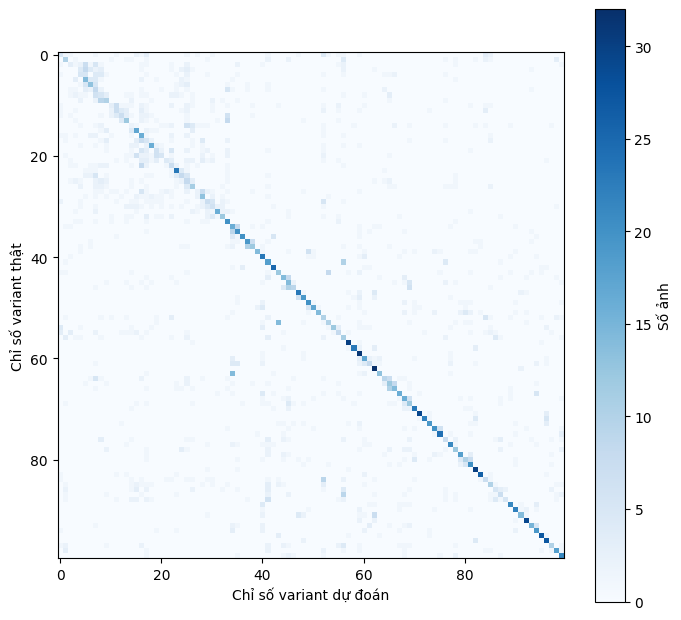

In [18]:
fig, ax = plt.subplots(figsize=(7.1, 6.4))
heat = ax.imshow(cm, cmap="Blues", interpolation="nearest")
ax.set(xlabel="Chỉ số variant dự đoán", ylabel="Chỉ số variant thật")
fig.colorbar(heat, ax=ax, label="Số ảnh")
fig.tight_layout()
plt.show()

### 4.5. Xem ảnh dự đoán sai

Ưu tiên bốn ảnh thuộc cặp biến thể bị nhầm nhiều nhất.

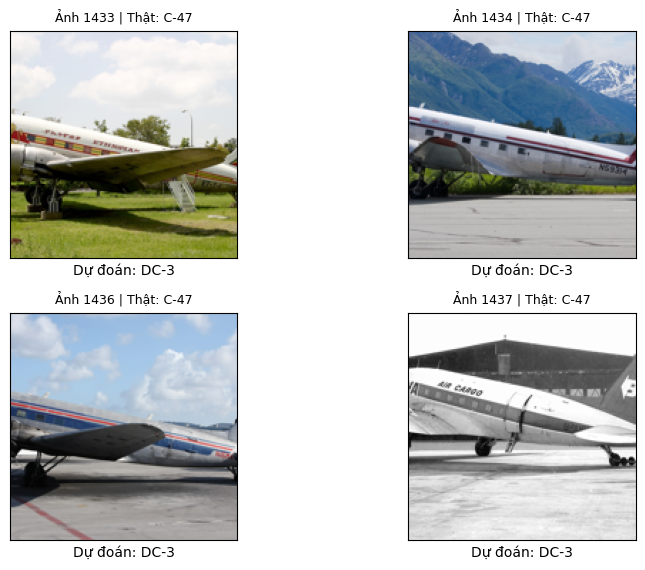

In [19]:
mistakes = np.flatnonzero(test["truth"] != test["pred"])
most_confused = {pairs[0][1], pairs[0][2]}
chosen = [i for i in mistakes
          if {names[test["truth"][i]], names[test["pred"][i]]} == most_confused]
if len(chosen) < 4:
    chosen.extend(i for i in mistakes if i not in chosen)
fig, axes = plt.subplots(2, 2, figsize=(9.4, 5.8))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat, chosen[:4]):
    image, label = test_set[int(idx)]
    image = image * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"Ảnh {idx} | Thật: {names[label]}", fontsize=9)
    ax.set_xlabel(f"Dự đoán: {names[test['pred'][idx]]}")
    ax.axis("on")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

## Bước 5. Lưu và kiểm tra mô hình

### 5.1. Lưu checkpoint

Lưu trọng số, tên lớp và cấu hình tiền xử lý.

In [20]:
checkpoint_path = Path("EfficientNetB0_FGVCAircraft.pt")
torch.save({
    "architecture": "efficientnet_b0", "pretrained": weights.name,
    "class_names": names, "image_size": IMAGE_SIZE, "resize_size": RESIZE_SIZE,
    "mean": mean, "std": std, "interpolation": "bicubic", "remove_bottom_pixels": 20,
    "selected_stage": selected["stage"], "epoch": selected["epoch"],
    "validation_loss": selected["val_loss"],
    "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
}, checkpoint_path)

### 5.2. Tải lại và đối chiếu dự đoán

Đối chiếu logits của mô hình gốc và mô hình đã tải lại trên cùng một ảnh validation.

In [21]:
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored = models.efficientnet_b0(weights=None)
restored.classifier[-1] = nn.Linear(restored.classifier[-1].in_features, len(saved["class_names"]))
restored.load_state_dict(saved["state_dict"])
restored = restored.to(device=device, memory_format=torch.channels_last).eval()
sample, sample_label = val_set[0]
with torch.inference_mode():
    sample_batch = move_images(sample.unsqueeze(0))
    original_logits = model(sample_batch)
    restored_logits = restored(sample_batch)
torch.testing.assert_close(original_logits, restored_logits)
prediction = int(restored_logits.argmax(1))
print(f"Checkpoint: {checkpoint_path} | Logits khớp sau khi tải lại.")
print(f"Ảnh validation đầu tiên: thật {names[sample_label]} | dự đoán {names[prediction]}")

Checkpoint: EfficientNetB0_FGVCAircraft.pt | Logits khớp sau khi tải lại.
Ảnh validation đầu tiên: thật 707-320 | dự đoán DC-8


## Kết quả

Ô dưới đây lấy số liệu từ hai giai đoạn huấn luyện và tập test vừa chạy. Chỉ số trung bình theo lớp được tính từ đường chéo của ma trận nhầm lẫn sau khi chuẩn hóa theo từng hàng.

In [22]:
class_accuracy = cm.diagonal() / cm.sum(axis=1).clip(min=1)
correct = int((test["truth"] == test["pred"]).sum())
error_count, variant_a, variant_b = pairs[0]
print(f"Linear Probe — Top-1 validation: {probe_best['val_acc']:.2%}, loss: {probe_best['val_loss']:.4f}")
print(f"Partial FT — Top-1 validation: {partial_best['val_acc']:.2%}, loss: {partial_best['val_loss']:.4f}")
print(f"Checkpoint: {selected['stage']}, epoch {selected['epoch']}")
print(f"Top-1 test: {test['acc']:.2%} ({correct:,}/{len(test_set):,} ảnh)")
print(f"Top-5 test: {test['top5']:.2%} | Macro-F1: {test['macro_f1']:.4f}")
print(f"Accuracy trung bình theo lớp: {class_accuracy.mean():.2%}")
if error_count > 0:
    print(f"Cặp nhầm nhiều nhất: {variant_a} / {variant_b}, {error_count} ảnh tính cả hai chiều.")

Linear Probe — Top-1 validation: 37.92%, loss: 2.5428
Partial FT — Top-1 validation: 44.67%, loss: 2.4699
Checkpoint: Partial FT, epoch 2
Top-1 test: 43.11% (1,437/3,333 ảnh)
Top-5 test: 74.05% | Macro-F1: 0.4298
Accuracy trung bình theo lớp: 43.09%
Cặp nhầm nhiều nhất: C-47 / DC-3, 22 ảnh tính cả hai chiều.
